# EN3150 Assignment 03: Train & evaluate everything (Kaggle / Colab)

Runs every experiment the assignment needs **on one GPU**, so the *time per epoch* column is comparable across models.

| Assignment part | Cells |
|---|---|
| 1. Data prep (64×64, 70/15/15) | Step 2 |
| 3. Optimizer comparison (Adam vs SGD vs SGD+Momentum) | Step 4 |
| 4. Model A & B, 20 epochs, loss curves, test metrics, A-vs-B table | Steps 3, 6, 7 |
| 5. Fine-tune MobileNetV2 + EfficientNet-B0, params + size (MB) | Step 5 |
| 6. Model B vs SOTA comparison | Step 7 |

**Before running:**
- **Kaggle:** right sidebar → *Accelerator* = **GPU T4 x2** (or P100), *Internet* = **On**. Then use **Save Version → Save & Run All (Commit)** so it runs in the background, and download from the *Output* tab.
- **Colab:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Keep the tab open; Step 8 saves results to Google Drive.

## Step 0: Settings

In [1]:
REPO_URL = "https://github.com/rash200319/CNN-for-image-classification.git"
# Private repo? use: "https://<YOUR_GITHUB_TOKEN>@github.com/rash200319/CNN-for-image-classification.git"

EPOCHS_CUSTOM = 20   # assignment: at least 20 epochs for Model A and Model B
EPOCHS_SOTA   = 5    # fine-tuning epochs for the pretrained models
RUN_MODEL_A_OPTIMIZER_SWEEP = False  # True = also compare SGD / SGD+Momentum for Model A (optional, +~2 runs)

## Step 1: Detect platform, check GPU, clone the repo

In [2]:
import os, sys, subprocess, pathlib

ON_KAGGLE = os.path.exists("/kaggle")
ON_COLAB  = "google.colab" in sys.modules
WORK_DIR  = pathlib.Path("/kaggle/working") if ON_KAGGLE else pathlib.Path("/content")
REPO_DIR  = WORK_DIR / "CNN-for-image-classification"
print("Platform:", "Kaggle" if ON_KAGGLE else "Colab" if ON_COLAB else "Other/local")

import torch
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU, enable it in the notebook settings, otherwise training is very slow.")

import socket, shutil
def has_internet(host="github.com"):
    try:
        socket.gethostbyname(host); return True
    except OSError:
        return False

HAS_INTERNET = has_internet()
print("Internet:", HAS_INTERNET)

if HAS_INTERNET:
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
elif not REPO_DIR.exists():
    # Offline fallback: repo uploaded as a Kaggle dataset (any folder under /kaggle/input containing src/train.py)
    found = next((p.parent.parent for p in pathlib.Path("/kaggle/input").rglob("src/train.py")), None)
    if found is None:
        raise RuntimeError(
            "No internet. On Kaggle: right sidebar -> Session options -> Internet = ON "
            "(needs a phone-verified account, Settings -> Phone verification), then Restart & Run All.\n"
            "Or upload the repo folder as a Kaggle dataset and attach it with '+ Add Input'.")
    shutil.copytree(found, REPO_DIR, ignore=shutil.ignore_patterns(".git", "__pycache__"))
    print("Copied repo from", found)

os.chdir(REPO_DIR)
print("Working in:", os.getcwd())

Platform: Kaggle
torch 2.11.0+cu128 | CUDA available: True
GPU: Tesla T4
Internet: True


Cloning into '/kaggle/working/CNN-for-image-classification'...


Working in: /kaggle/working/CNN-for-image-classification


In [3]:
# torch / torchvision / sklearn / pandas / matplotlib are preinstalled on Kaggle & Colab
!pip install -q tqdm

## Step 2: Get the EuroSAT RGB dataset
The code expects the images at `archive/EuroSAT/<ClassName>/*.jpg`. This cell:
1. looks for an already-attached copy (a Kaggle dataset under `/kaggle/input`, or a folder in your Google Drive), otherwise
2. downloads EuroSAT RGB (~90 MB) with `torchvision`,

then links it to `archive/EuroSAT`.

In [4]:
from pathlib import Path

def find_eurosat(root):
    root = Path(root)
    if not root.exists():
        return None
    for p in root.rglob("AnnualCrop"):
        if p.is_dir() and (p.parent / "SeaLake").is_dir() and any(p.glob("*.jpg")):
            return p.parent
    return None

search_roots = ["/kaggle/input"]
if ON_COLAB:
    # Optional: put your EuroSAT_RGB folder in Google Drive and it will be used instead of downloading
    from google.colab import drive
    drive.mount("/content/drive")
    search_roots.append("/content/drive/MyDrive")

data_root = None
for r in search_roots:
    data_root = find_eurosat(r)
    if data_root:
        break

if data_root is None:
    print("No local copy found, downloading EuroSAT RGB with torchvision ...")
    from torchvision.datasets import EuroSAT
    EuroSAT(root="/tmp/eurosat_dl", download=True)
    data_root = find_eurosat("/tmp/eurosat_dl")

assert data_root is not None, "EuroSAT not found / download failed"
print("Dataset folder:", data_root)

link = REPO_DIR / "archive" / "EuroSAT"
link.parent.mkdir(exist_ok=True)
if link.is_symlink() or link.exists():
    link.unlink()
link.symlink_to(data_root, target_is_directory=True)

classes = sorted(d.name for d in link.iterdir() if d.is_dir())
n_imgs = sum(len(list((link / c).glob("*.jpg"))) for c in classes)
print(f"{len(classes)} classes, {n_imgs} images:", classes)
assert len(classes) == 10 and n_imgs == 27000

No local copy found, downloading EuroSAT RGB with torchvision ...


100%|██████████| 94.3M/94.3M [00:01<00:00, 76.9MB/s]


Dataset folder: /tmp/eurosat_dl/eurosat/2750
10 classes, 27000 images: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [5]:
# Sanity check: split sizes + parameter counts (Model B must be <= 100k)
from src.data.dataset import get_dataloaders
from src.models.model_a import ModelA
from src.models.model_b import ModelB
from src.utils import count_parameters

tr, va, te, cls = get_dataloaders()
print(f"train={len(tr.dataset)}  val={len(va.dataset)}  test={len(te.dataset)}")
print(f"Model A params: {count_parameters(ModelA(10)):,}")
print(f"Model B params: {count_parameters(ModelB(10)):,}  (limit 100,000)")

train=18900  val=4049  test=4051
Model A params: 549,290
Model B params: 13,288  (limit 100,000)


## Step 3: Train Model A and Model B with Adam (Part 4)

In [6]:
!python -m src.train --model a --optimizer adam --lr 1e-3 --epochs {EPOCHS_CUSTOM} --run-name final_a_adam

final_a_adam: 549,290 trainable params on cuda
final_a_adam: 100%|█████████████████████████████| 20/20 [03:23<00:00, 10.16s/it]
Done. Best val_acc=0.9054. Logs in /kaggle/working/CNN-for-image-classification/outputs/final_a_adam


In [7]:
!python -m src.train --model b --optimizer adam --lr 1e-3 --epochs {EPOCHS_CUSTOM} --run-name modelb_adam

modelb_adam: 13,288 trainable params on cuda
modelb_adam: 100%|██████████████████████████████| 20/20 [03:25<00:00, 10.28s/it]
Done. Best val_acc=0.8945. Logs in /kaggle/working/CNN-for-image-classification/outputs/modelb_adam


## Step 4: Optimizer comparison on Model B: plain SGD vs SGD + Momentum (Part 3)

In [8]:
!python -m src.train --model b --optimizer sgd          --lr 1e-2                --epochs {EPOCHS_CUSTOM} --run-name modelb_sgd
!python -m src.train --model b --optimizer sgd_momentum --lr 1e-2 --momentum 0.9 --epochs {EPOCHS_CUSTOM} --run-name modelb_sgd_momentum

modelb_sgd: 13,288 trainable params on cuda
modelb_sgd: 100%|███████████████████████████████| 20/20 [03:26<00:00, 10.32s/it]
Done. Best val_acc=0.8019. Logs in /kaggle/working/CNN-for-image-classification/outputs/modelb_sgd
modelb_sgd_momentum: 13,288 trainable params on cuda
modelb_sgd_momentum: 100%|██████████████████████| 20/20 [03:26<00:00, 10.34s/it]
Done. Best val_acc=0.8785. Logs in /kaggle/working/CNN-for-image-classification/outputs/modelb_sgd_momentum


In [9]:
# Optional: same comparison for Model A
if RUN_MODEL_A_OPTIMIZER_SWEEP:
    !python -m src.train --model a --optimizer sgd          --lr 1e-2                --epochs {EPOCHS_CUSTOM} --run-name modela_sgd
    !python -m src.train --model a --optimizer sgd_momentum --lr 1e-2 --momentum 0.9 --epochs {EPOCHS_CUSTOM} --run-name modela_sgd_momentum

## Step 5: Fine-tune the two lightweight pretrained models (Part 5)

In [10]:
!python -m src.train --model mobilenet_v2    --optimizer adam --lr 1e-4 --img-size 128 --epochs {EPOCHS_SOTA} --run-name final_mobilenet_v2
!python -m src.train --model efficientnet_b0 --optimizer adam --lr 1e-4 --img-size 64  --epochs {EPOCHS_SOTA} --run-name final_efficientnet_b0

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100%|███████████████████████████████████████| 13.6M/13.6M [00:00<00:00, 116MB/s]
final_mobilenet_v2: 2,236,682 trainable params on cuda
final_mobilenet_v2: 100%|█████████████████████████| 5/5 [02:24<00:00, 28.86s/it]
Done. Best val_acc=0.9822. Logs in /kaggle/working/CNN-for-image-classification/outputs/final_mobilenet_v2
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|███████████████████████████████████████| 20.5M/20.5M [00:00<00:00, 132MB/s]
final_efficientnet_b0: 4,020,358 trainable params on cuda
final_efficientnet_b0: 100%|██████████████████████| 5/5 [01:33<00:00, 18.66s/it]
Done. Best val_acc=0.9699. Logs in /kaggle/working/CNN-for-image-classification/outputs/final_efficientnet_b0


## Step 6: Evaluate on the test set and plot loss curves

In [11]:
RUNS = {  # run_name: (model flag, img size)
    "final_a_adam":          ("a", 64),
    "modelb_adam":           ("b", 64),
    "modelb_sgd":            ("b", 64),
    "modelb_sgd_momentum":   ("b", 64),
    "final_mobilenet_v2":    ("mobilenet_v2", 128),
    "final_efficientnet_b0": ("efficientnet_b0", 64),
}
if RUN_MODEL_A_OPTIMIZER_SWEEP:
    RUNS.update({"modela_sgd": ("a", 64), "modela_sgd_momentum": ("a", 64)})

for run, (m, size) in RUNS.items():
    print(f"\n===== {run} =====")
    !python -m src.evaluate --model {m} --checkpoint outputs/{run}/best_model.pt --img-size {size}
    !python -m src.plot_history --run-dir outputs/{run}


===== final_a_adam =====
test_accuracy=0.9146 precision_macro=0.9137 recall_macro=0.9118
params=549,290 checkpoint_size_kb=2150.1
Confusion matrix saved to outputs/final_a_adam/confusion_matrix.png
Full metrics saved to outputs/final_a_adam/metrics.json
Saved plot to outputs/final_a_adam/loss_curve.png

===== modelb_adam =====
test_accuracy=0.8961 precision_macro=0.8975 recall_macro=0.8918
params=13,288 checkpoint_size_kb=63.9
Confusion matrix saved to outputs/modelb_adam/confusion_matrix.png
Full metrics saved to outputs/modelb_adam/metrics.json
Saved plot to outputs/modelb_adam/loss_curve.png

===== modelb_sgd =====
test_accuracy=0.8126 precision_macro=0.8095 recall_macro=0.8042
params=13,288 checkpoint_size_kb=63.9
Confusion matrix saved to outputs/modelb_sgd/confusion_matrix.png
Full metrics saved to outputs/modelb_sgd/metrics.json
Saved plot to outputs/modelb_sgd/loss_curve.png

===== modelb_sgd_momentum =====
test_accuracy=0.8771 precision_macro=0.8822 recall_macro=0.8723
params

In [12]:
# Overlay plots: optimizer comparison (Part 3) and Model A vs B (Part 4)
!python -m src.plot_history --run-dir outputs/modelb_adam --run-dir outputs/modelb_sgd --run-dir outputs/modelb_sgd_momentum --out outputs/modelb_optimizer_comparison.png
!python -m src.plot_history --run-dir outputs/final_a_adam --run-dir outputs/modelb_adam --out outputs/modelA_vs_modelB_loss.png
if RUN_MODEL_A_OPTIMIZER_SWEEP:
    !python -m src.plot_history --run-dir outputs/final_a_adam --run-dir outputs/modela_sgd --run-dir outputs/modela_sgd_momentum --out outputs/modela_optimizer_comparison.png

Saved plot to outputs/modelb_optimizer_comparison.png
Saved plot to outputs/modelA_vs_modelB_loss.png


## Step 7: Results tables for the report (Parts 3, 4, 5, 6)

In [13]:
import json, pandas as pd
from IPython.display import display, Image, Markdown

rows = []
for run in RUNS:
    d = Path("outputs") / run
    m = json.load(open(d / "metrics.json"))
    h = pd.read_csv(d / "history.csv")
    rows.append({
        "run": run,
        "params": m["trainable_params"],
        "size_KB": round(m["checkpoint_size_kb"], 1),
        "size_MB": round(m["checkpoint_size_kb"] / 1024, 3),
        "epochs": len(h),
        "median_s_per_epoch": round(h["epoch_time_sec"].median(), 2),
        "best_val_acc_%": round(100 * h["val_acc"].max(), 2),
        "test_acc_%": round(100 * m["test_accuracy"], 2),
        "precision_macro": round(m["precision_macro"], 4),
        "recall_macro": round(m["recall_macro"], 4),
        "f1_macro": round(m["f1_macro"], 4),
    })
df = pd.DataFrame(rows).set_index("run")
df.to_csv("outputs/all_results.csv")

display(Markdown("### Part 3: Optimizer comparison (Model B)"))
display(df.loc[["modelb_adam", "modelb_sgd", "modelb_sgd_momentum"]])
display(Markdown("### Part 4: Model A vs Model B"))
display(df.loc[["final_a_adam", "modelb_adam"], ["params", "size_KB", "median_s_per_epoch", "test_acc_%"]])
display(Markdown("### Parts 5 & 6: Model B vs lightweight SOTA"))
display(df.loc[["modelb_adam", "final_mobilenet_v2", "final_efficientnet_b0"],
               ["params", "size_MB", "median_s_per_epoch", "test_acc_%", "precision_macro", "recall_macro"]])

print("GPU used:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print(df.to_markdown())

### Part 3: Optimizer comparison (Model B)

,params,size_KB,size_MB,epochs,median_s_per_epoch,best_val_acc_%,test_acc_%,precision_macro,recall_macro,f1_macro
run,,,,,,,,,,
modelb_adam,13288,63.9,0.062,20,10.26,89.45,89.61,0.8975,0.8918,0.8905
modelb_sgd,13288,63.9,0.062,20,10.30,80.19,81.26,0.8095,0.8042,0.8024
modelb_sgd_momentum,13288,63.9,0.062,20,10.31,87.85,87.71,0.8822,0.8723,0.8741


### Part 4: Model A vs Model B

,params,size_KB,median_s_per_epoch,test_acc_%
run,,,,
final_a_adam,549290,2150.1,10.02,91.46
modelb_adam,13288,63.9,10.26,89.61


### Parts 5 & 6: Model B vs lightweight SOTA

,params,size_MB,median_s_per_epoch,test_acc_%,precision_macro,recall_macro
run,,,,,,
modelb_adam,13288,0.062,10.26,89.61,0.8975,0.8918
final_mobilenet_v2,2236682,8.766,28.58,98.20,0.9814,0.9809
final_efficientnet_b0,4020358,15.622,18.49,97.51,0.9753,0.9734


GPU used: Tesla T4
| run                   |           params |   size_KB |   size_MB |   epochs |   median_s_per_epoch |   best_val_acc_% |   test_acc_% |   precision_macro |   recall_macro |   f1_macro |
|:----------------------|-----------------:|----------:|----------:|---------:|---------------------:|-----------------:|-------------:|------------------:|---------------:|-----------:|
| final_a_adam          | 549290           |    2150.1 |     2.1   |       20 |                10.02 |            90.54 |        91.46 |            0.9137 |         0.9118 |     0.912  |
| modelb_adam           |  13288           |      63.9 |     0.062 |       20 |                10.26 |            89.45 |        89.61 |            0.8975 |         0.8918 |     0.8905 |
| modelb_sgd            |  13288           |      63.9 |     0.062 |       20 |                10.3  |            80.19 |        81.26 |            0.8095 |         0.8042 |     0.8024 |
| modelb_sgd_momentum   |  13288           |  

In [14]:
# Per-class precision / recall (for the report's confusion-matrix discussion)
for run in ["final_a_adam", "modelb_adam", "final_mobilenet_v2", "final_efficientnet_b0"]:
    pc = json.load(open(f"outputs/{run}/metrics.json"))["per_class"]
    display(Markdown(f"**{run}**"))
    display(pd.DataFrame(pc).T.round(4))

**final_a_adam**

,precision,recall,f1,support
AnnualCrop,0.8609,0.9489,0.9027,450.0
Forest,0.9686,0.9600,0.9643,450.0
HerbaceousVegetation,0.8584,0.9002,0.8788,451.0
Highway,0.8462,0.8507,0.8484,375.0
Industrial,0.9696,0.9360,0.9525,375.0
Pasture,0.8875,0.9467,0.9161,300.0
PermanentCrop,0.8844,0.8160,0.8488,375.0
Residential,0.9756,0.9756,0.9756,450.0
River,0.8928,0.8213,0.8556,375.0
SeaLake,0.9931,0.9622,0.9774,450.0


**modelb_adam**

,precision,recall,f1,support
AnnualCrop,0.8367,0.9111,0.8723,450.0
Forest,0.9611,0.9889,0.9748,450.0
HerbaceousVegetation,0.8807,0.9002,0.8904,451.0
Highway,0.7551,0.8800,0.8128,375.0
Industrial,0.9525,0.9093,0.9304,375.0
Pasture,0.8701,0.9600,0.9128,300.0
PermanentCrop,0.8792,0.7760,0.8244,375.0
Residential,0.9253,0.9911,0.9571,450.0
River,0.9297,0.6347,0.7544,375.0
SeaLake,0.9842,0.9667,0.9753,450.0


**final_mobilenet_v2**

,precision,recall,f1,support
AnnualCrop,0.9628,0.9778,0.9702,450.0
Forest,0.9912,0.9956,0.9933,450.0
HerbaceousVegetation,0.9866,0.9778,0.9822,451.0
Highway,0.9812,0.9760,0.9786,375.0
Industrial,0.9867,0.9867,0.9867,375.0
Pasture,0.9666,0.9633,0.9649,300.0
PermanentCrop,0.9702,0.9547,0.9624,375.0
Residential,0.9956,0.9956,0.9956,450.0
River,0.9840,0.9813,0.9826,375.0
SeaLake,0.9890,1.0000,0.9945,450.0


**final_efficientnet_b0**

,precision,recall,f1,support
AnnualCrop,0.9500,0.9711,0.9604,450.0
Forest,0.9825,0.9956,0.9890,450.0
HerbaceousVegetation,0.9590,0.9845,0.9716,451.0
Highway,0.9810,0.9653,0.9731,375.0
Industrial,0.9893,0.9840,0.9866,375.0
Pasture,0.9727,0.9500,0.9612,300.0
PermanentCrop,0.9724,0.9387,0.9552,375.0
Residential,0.9868,0.9956,0.9912,450.0
River,0.9679,0.9653,0.9666,375.0
SeaLake,0.9911,0.9844,0.9877,450.0


### final_a_adam

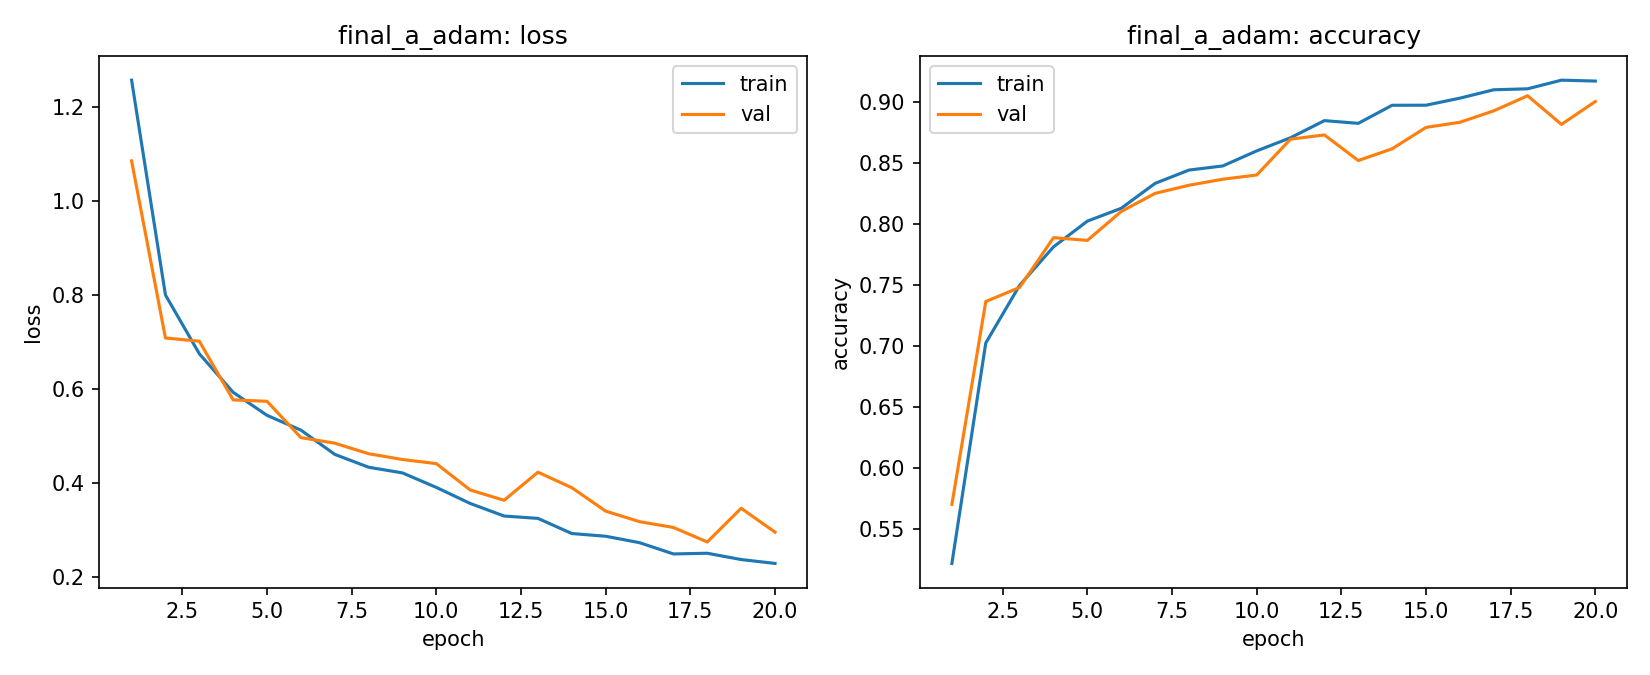

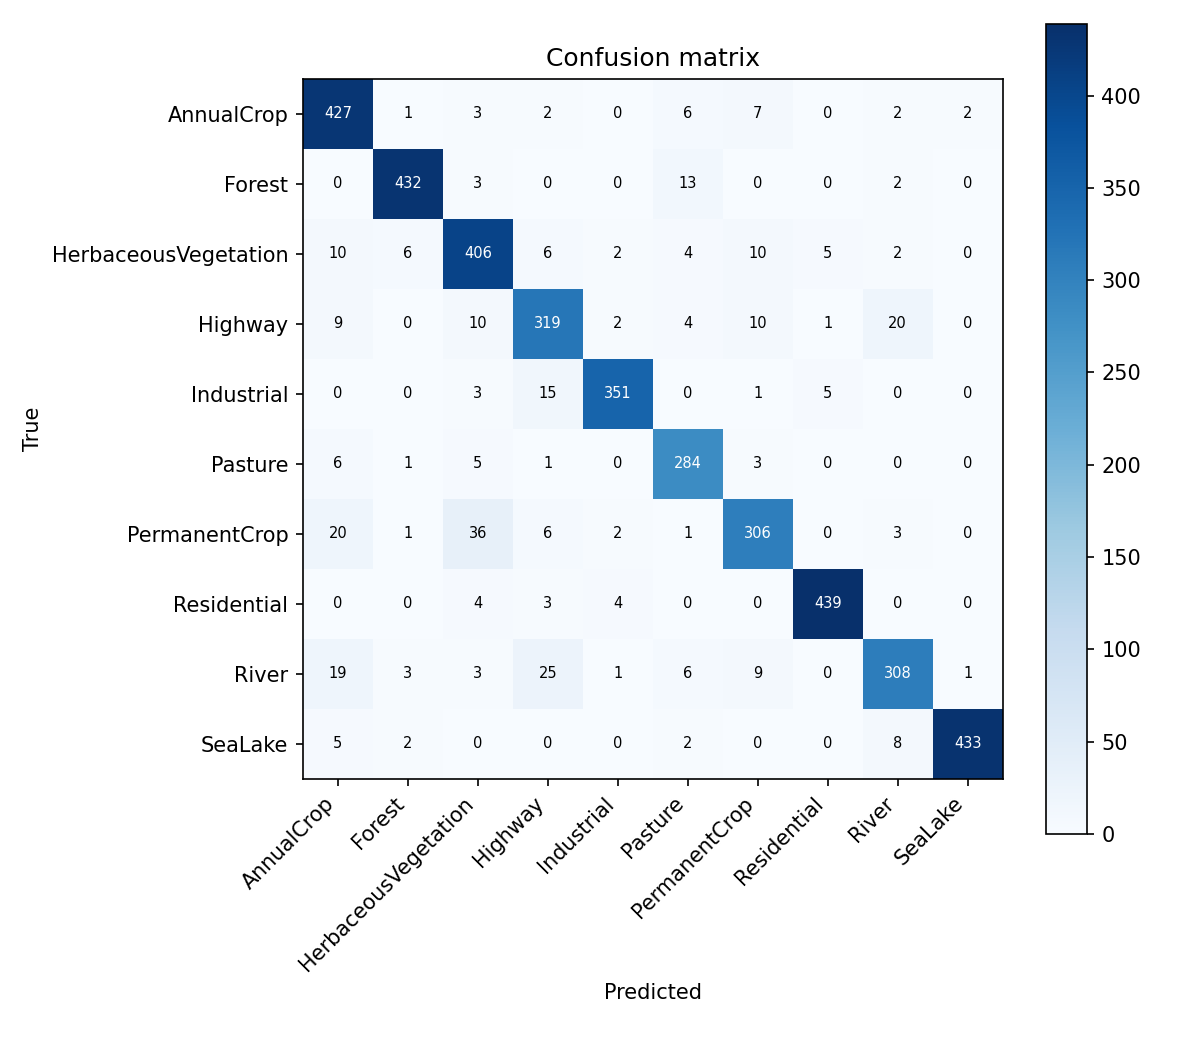

### modelb_adam

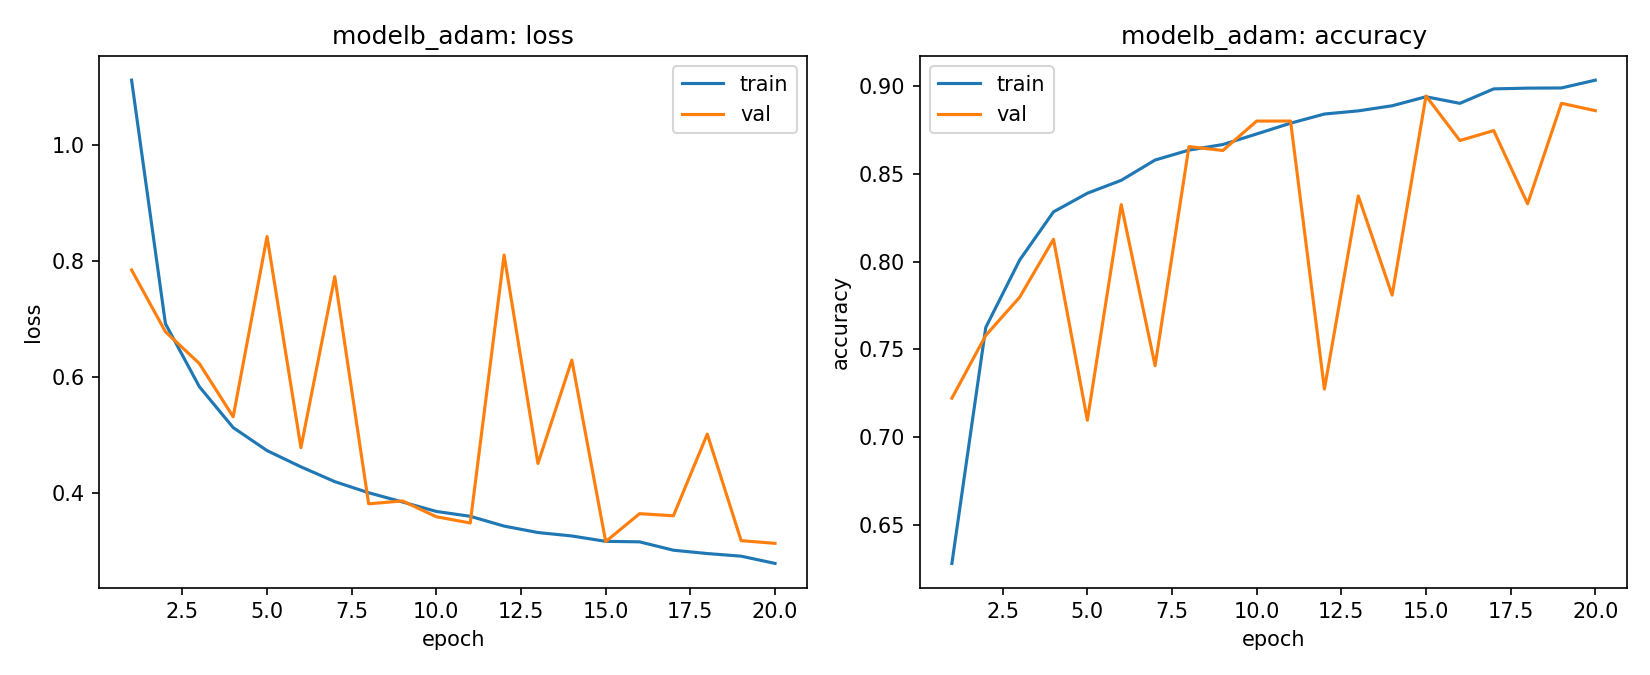

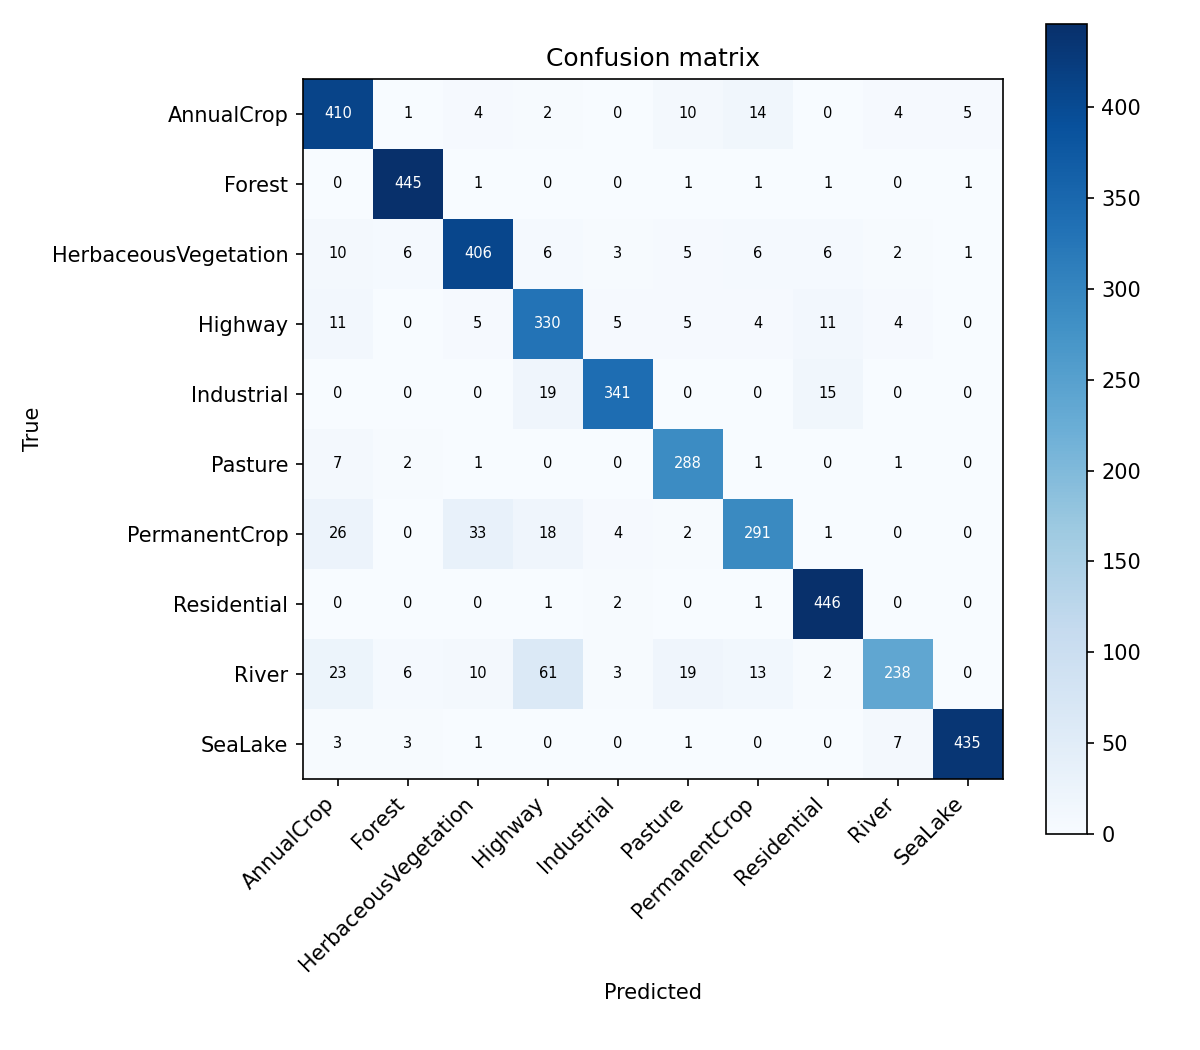

### modelb_sgd

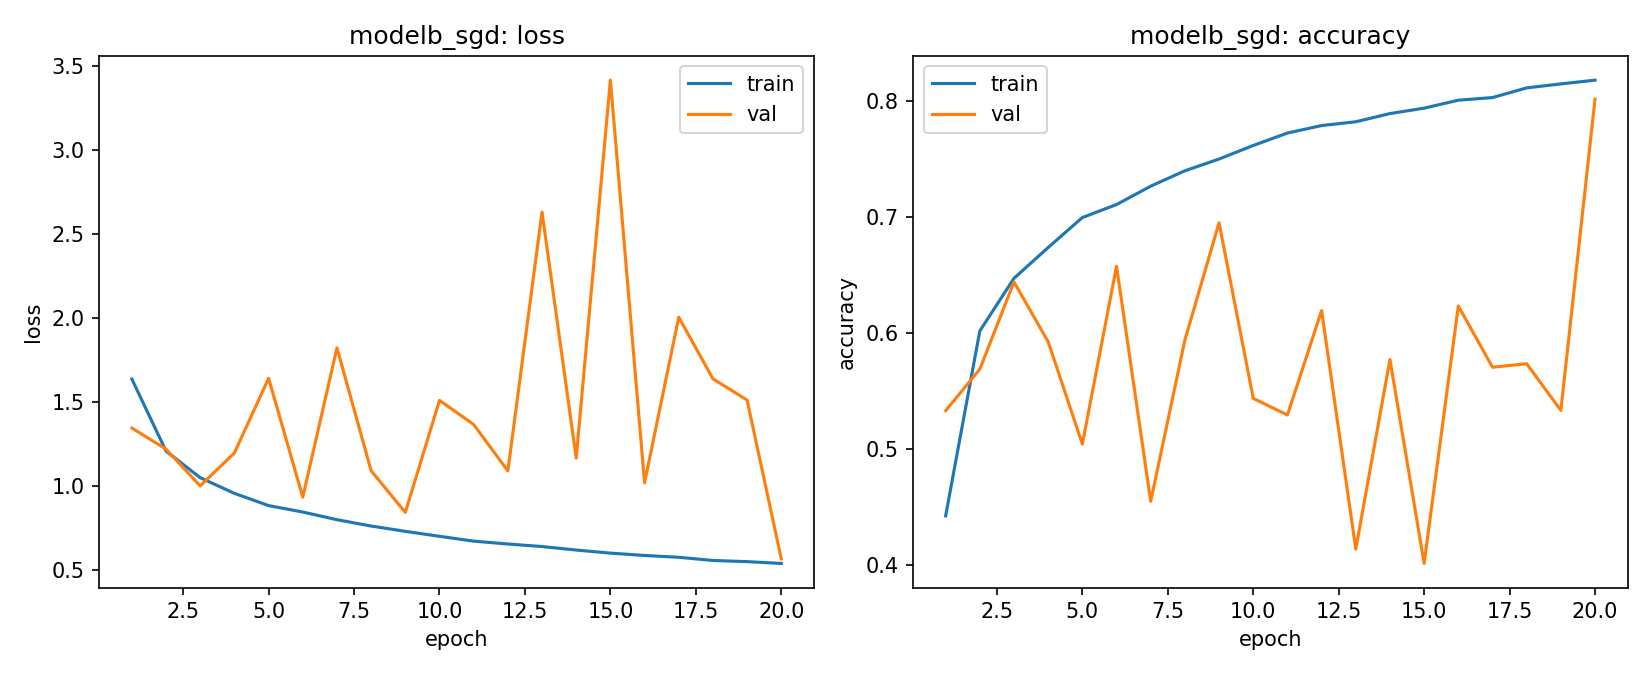

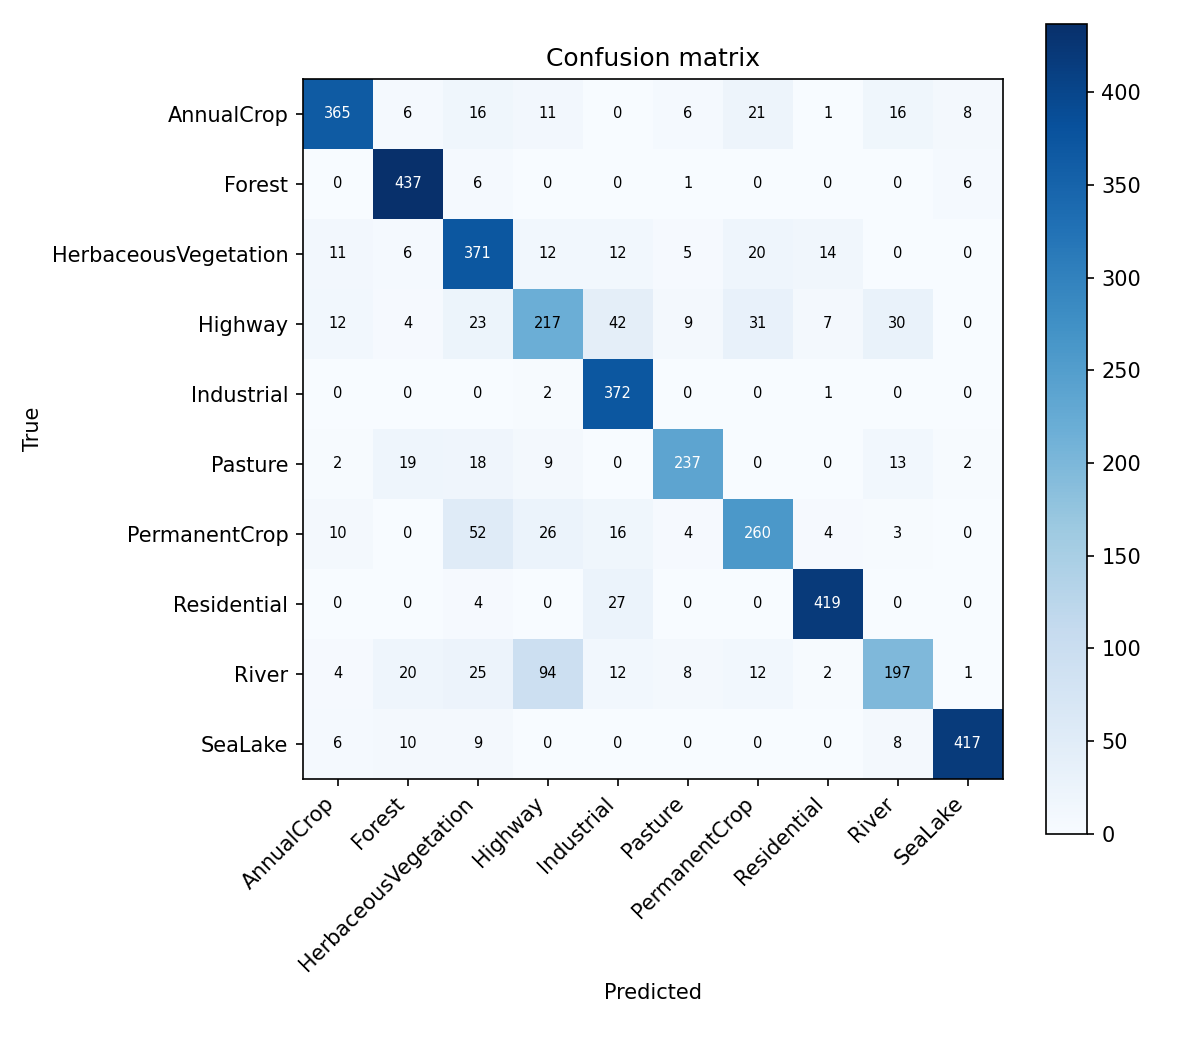

### modelb_sgd_momentum

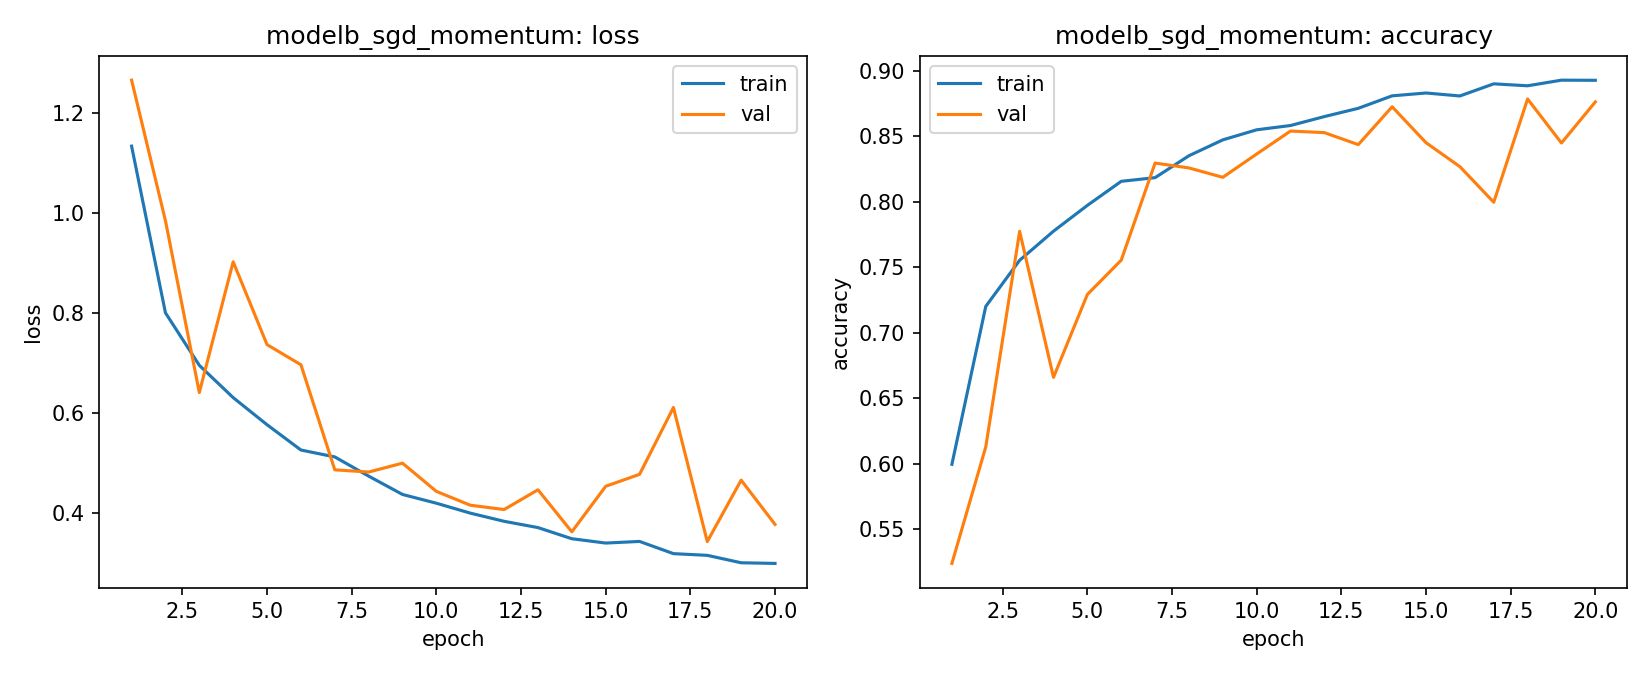

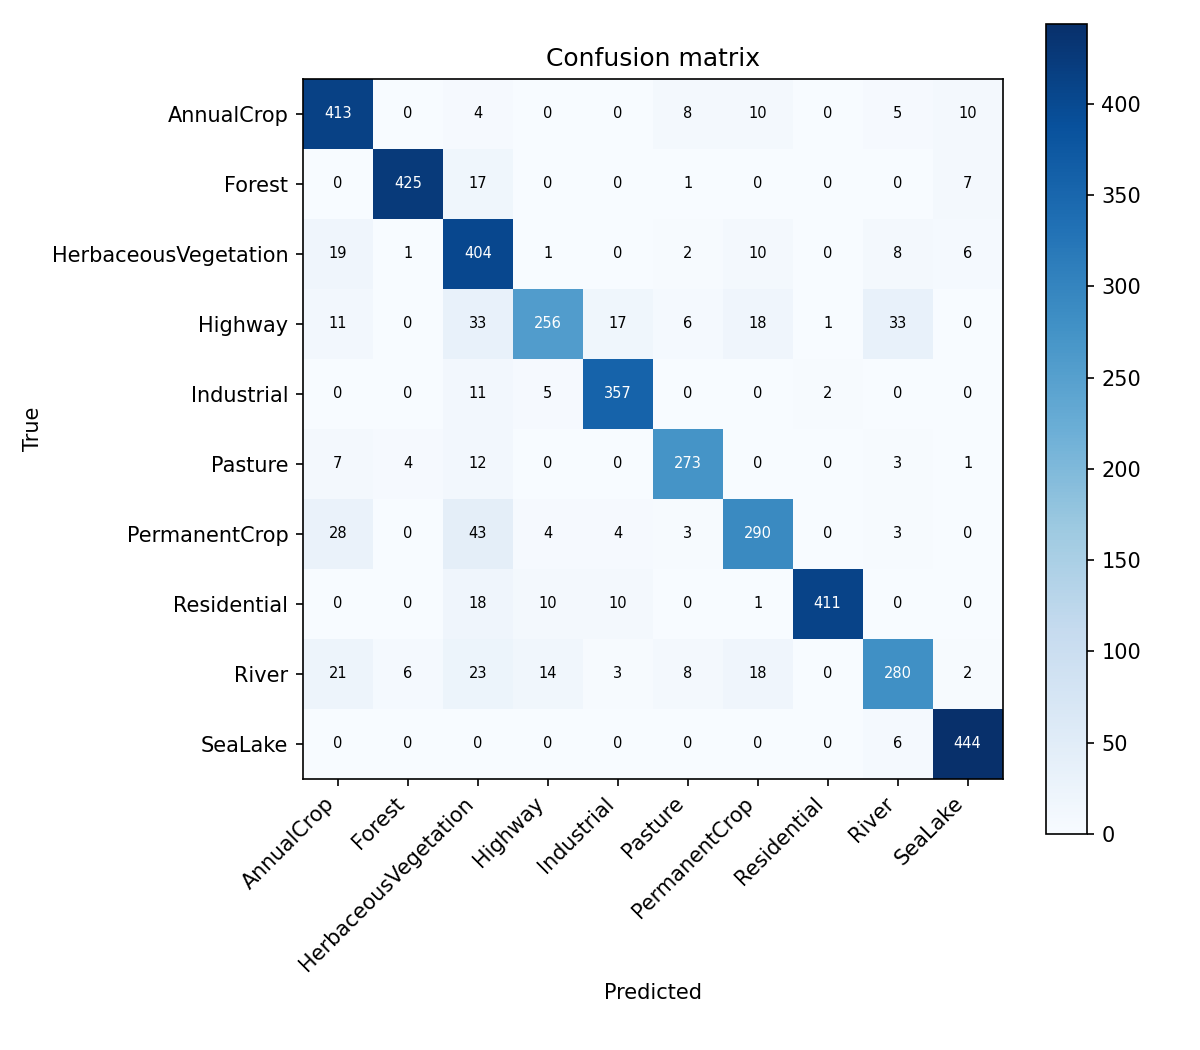

### final_mobilenet_v2

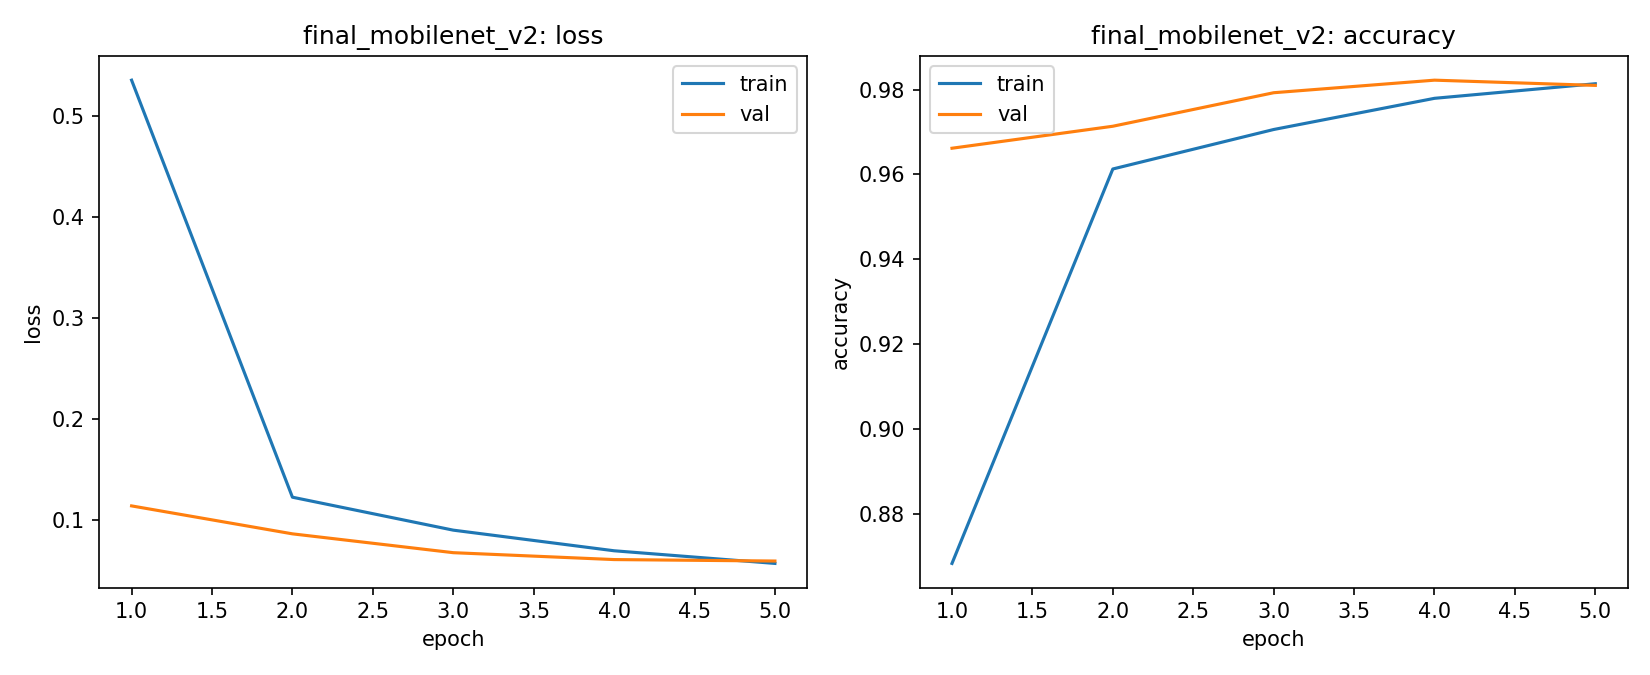

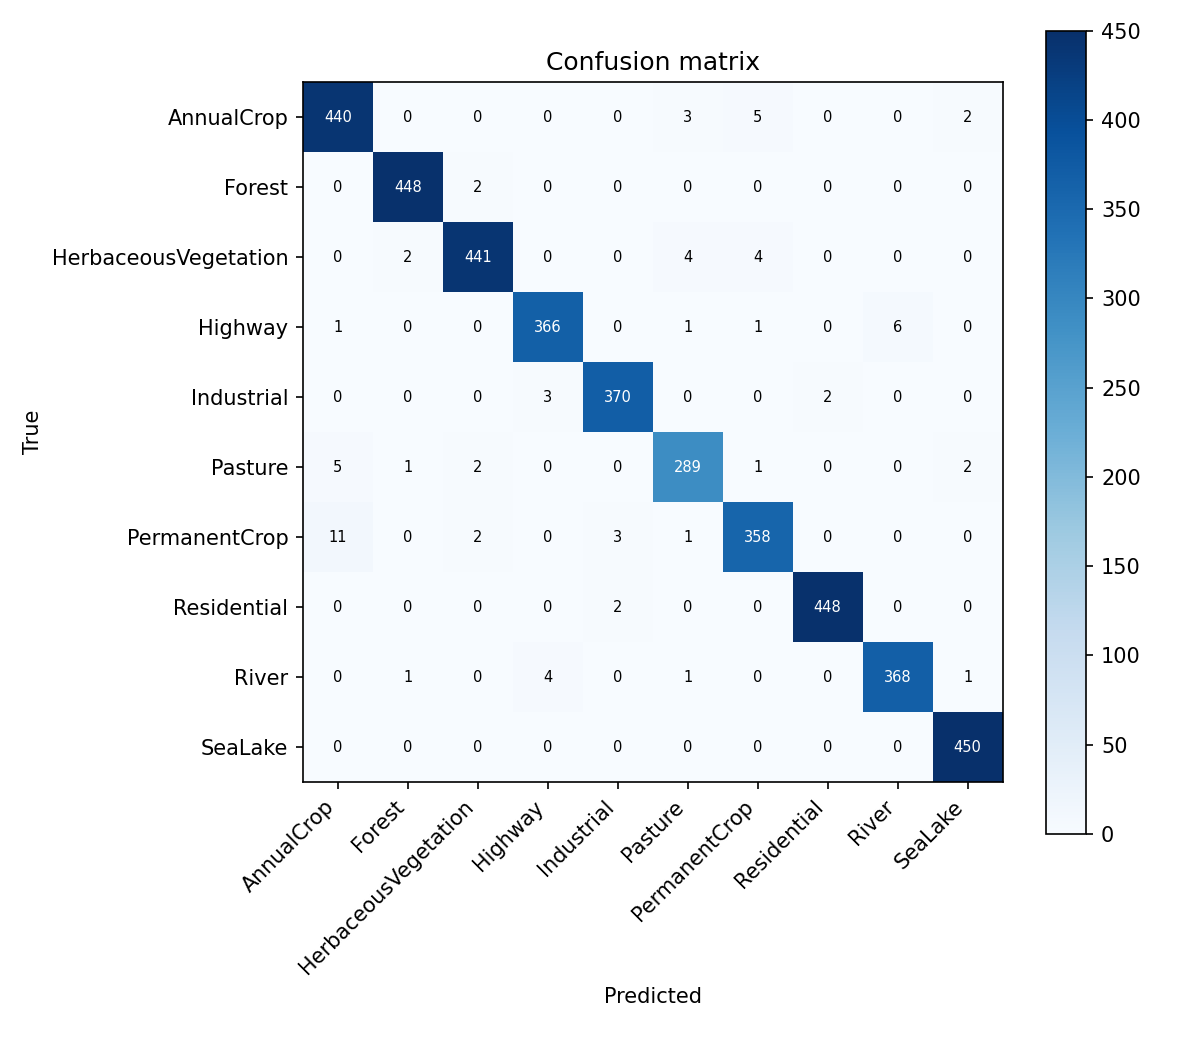

### final_efficientnet_b0

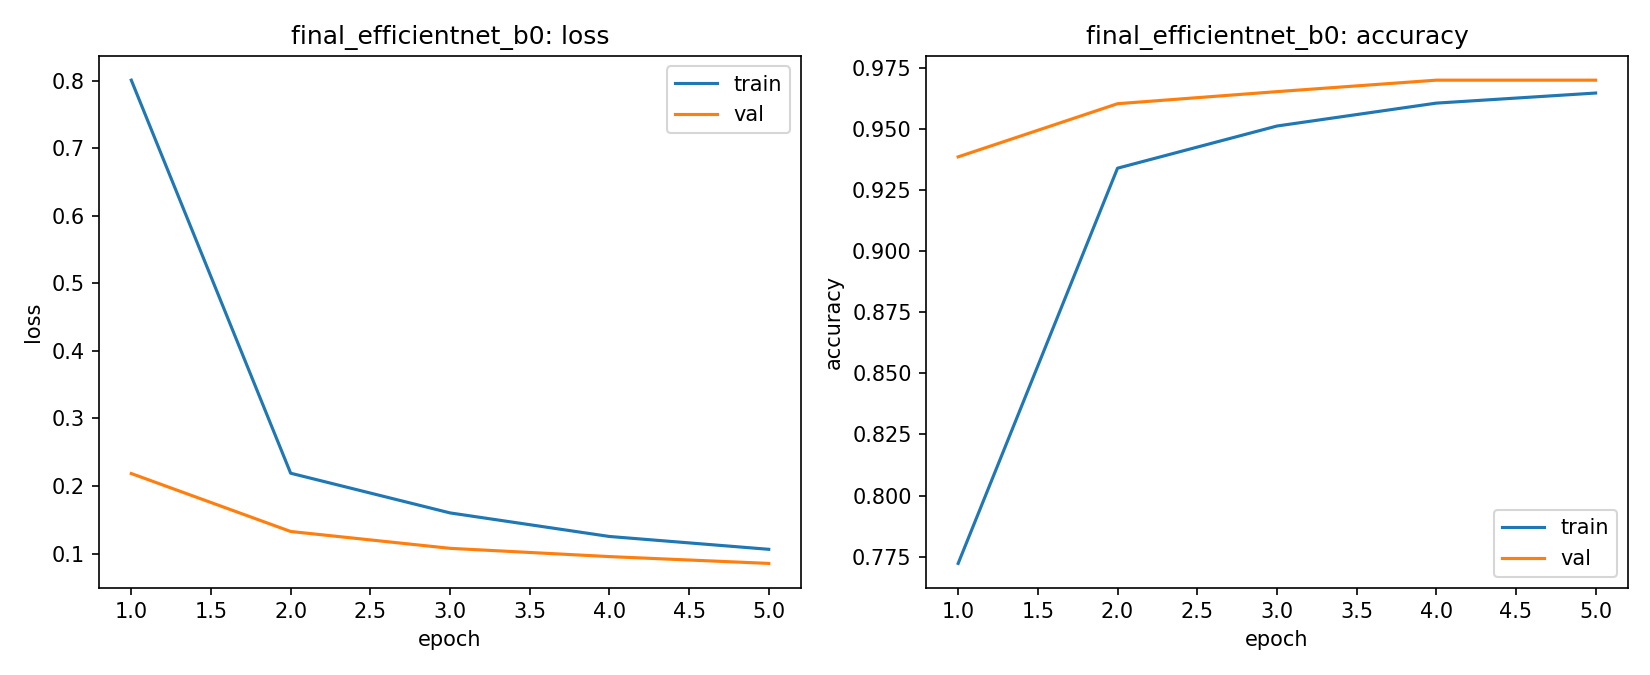

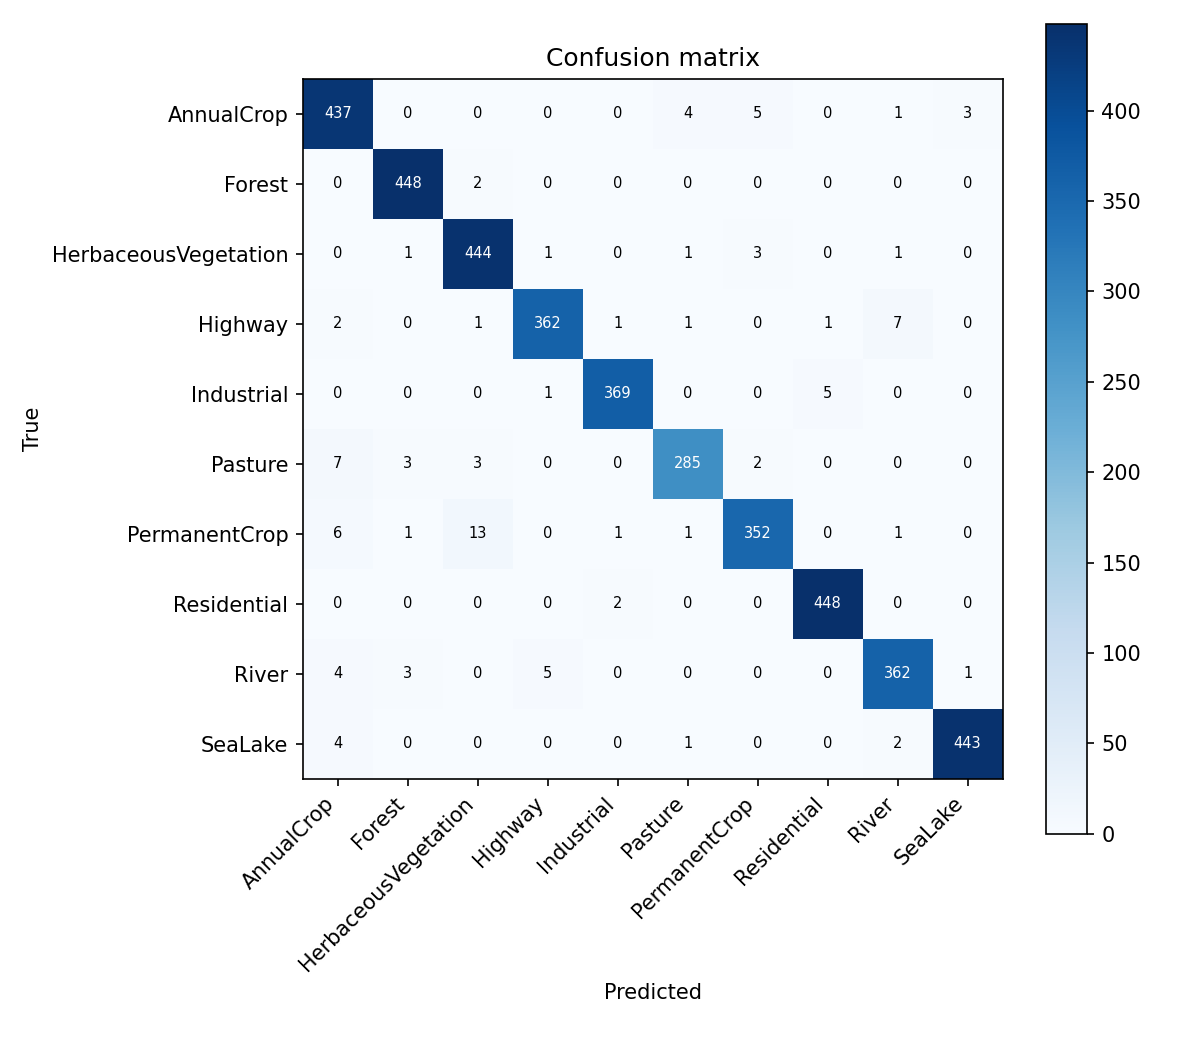

### modelb_optimizer_comparison.png

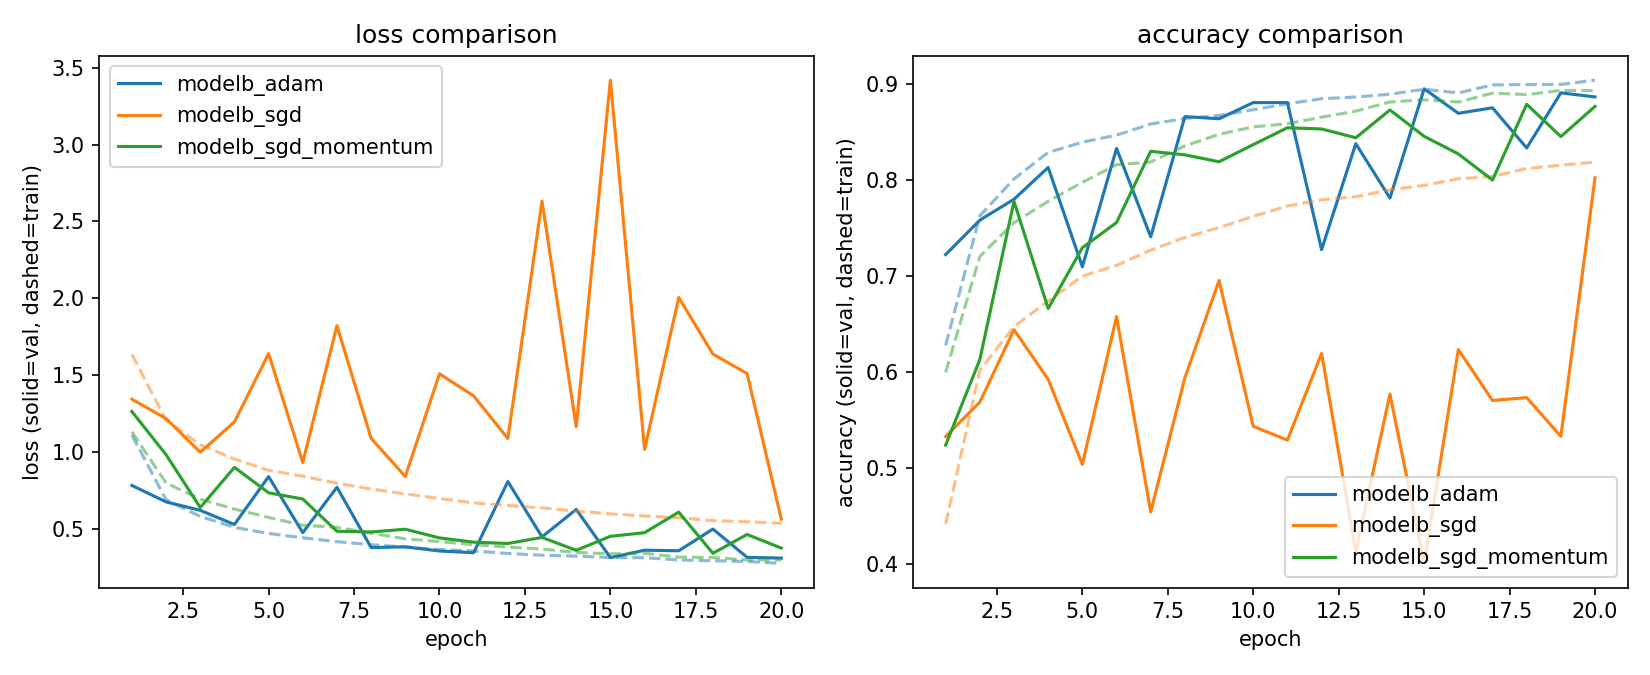

### modelA_vs_modelB_loss.png

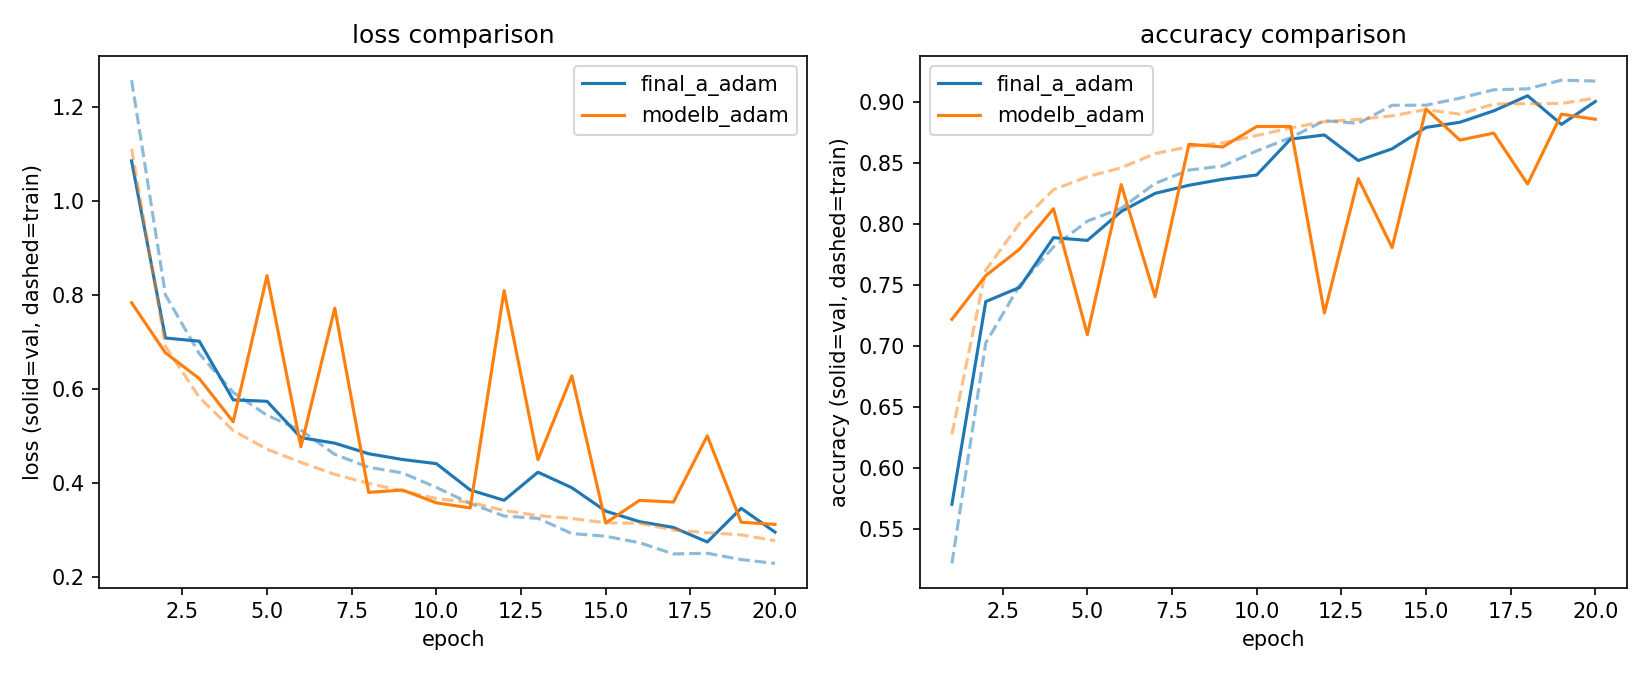

In [15]:
# Show all figures inline
for run in RUNS:
    display(Markdown(f"### {run}"))
    for f in ["loss_curve.png", "confusion_matrix.png"]:
        p = Path("outputs") / run / f
        if p.exists():
            display(Image(filename=str(p), width=520))
for f in ["modelb_optimizer_comparison.png", "modelA_vs_modelB_loss.png", "modela_optimizer_comparison.png"]:
    p = Path("outputs") / f
    if p.exists():
        display(Markdown(f"### {f}")); display(Image(filename=str(p), width=700))

## Step 8: Save / download the results
- **Kaggle:** `results.zip` is written to `/kaggle/working` and appears in the notebook's **Output** tab after the committed run finishes.
- **Colab:** it's copied to `MyDrive/EN3150_A03_results.zip` and also offered as a browser download.

Unzip it into your local repo so that `outputs/` and the figures can be used in `report/main.tex`.

In [16]:
import shutil
zip_path = shutil.make_archive(str(WORK_DIR / "results"), "zip", root_dir=REPO_DIR, base_dir="outputs")
print("Created", zip_path)

if ON_COLAB:
    shutil.copy(zip_path, "/content/drive/MyDrive/EN3150_A03_results.zip")
    print("Copied to Google Drive: MyDrive/EN3150_A03_results.zip")
    from google.colab import files
    files.download(zip_path)

Created /kaggle/working/results.zip
